# TRABALHO 3: Naïve Bayes, Árvores de Decisão e Random Forest
**Alexsandro Narducci, Cláudio Strohaecker Junior e Lucas Cândido Belletti**

**Execução:** mantenha na mesma pasta do notebook os arquivos `risco_credito.csv` e `credit.pkl` (no Colab, envie os dois para a sessão antes de executar). O arquivo `risco_credito.pkl` é gerado na Parte 1 e lido na Parte 2, então execute as células em ordem. Dependências: `pandas`, `numpy`, `seaborn`, `matplotlib`, `plotly`, `scikit-learn` e, opcionalmente, `yellowbrick` (a matriz de confusão da árvore usa o yellowbrick, com alternativa automática em scikit-learn caso ele não esteja instalado). Os resultados e gráficos já estão salvos.

**Conteúdo:** Parte 1 (Naïve Bayes) e Parte 2 (Árvore de Decisão e Random Forest).

# PARTE 1: Algoritmo Naïve Bayes

Nesta primeira parte do Trabalho você irá aplicar o algoritmo de Naïve Bayes na base de dados de risco de crédito discutida em aula. Para isso você deve primeiramente importar as bibliotecas necessárias.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

**Importação da base de dados**

In [2]:
# importe a base de dados de risco de crédito e nomeie com: dataset_risco_credito
dataset_risco_credito = pd.read_csv('risco_credito.csv')

In [3]:
# imprima a base de dados para uma primeira avaliação dos dados
print(dataset_risco_credito)
print()
print('Dimensões (linhas, colunas):', dataset_risco_credito.shape)
print('Registros por classe de risco:')
print(dataset_risco_credito['risco'].value_counts())

        historia divida garantias     renda     risco
0           ruim   alta   nenhuma      0_15      alto
1   desconhecida   alta   nenhuma     15_35      alto
2   desconhecida  baixa   nenhuma     15_35  moderado
3   desconhecida  baixa   nenhuma  acima_35      alto
4   desconhecida  baixa   nenhuma  acima_35     baixo
5   desconhecida  baixa  adequada  acima_35     baixo
6           ruim  baixa   nenhuma      0_15      alto
7           ruim  baixa  adequada  acima_35  moderado
8            boa  baixa   nenhuma  acima_35     baixo
9            boa   alta  adequada  acima_35     baixo
10           boa   alta   nenhuma      0_15      alto
11           boa   alta   nenhuma     15_35  moderado
12           boa   alta   nenhuma  acima_35     baixo
13          ruim   alta   nenhuma     15_35      alto

Dimensões (linhas, colunas): (14, 5)
Registros por classe de risco:
risco
alto        6
baixo       5
moderado    3
Name: count, dtype: int64


## 1 - Pré-Processamento dos dados

a) DIVISÃO DA BASE DE DADOS

Separe a base de dados dataset_risco_credito em:
 - variável x, com nome: X_risco_credito
 - classe y, com nome: y_risco_credito

DICA: você pode utilizar .iloc para selecionar as colunas da matriz e .values para converter para o numpy array.

In [4]:
# As 4 primeiras colunas (historia, divida, garantias, renda) são os previsores
# e a última coluna (risco) é a classe.
# (.values / .to_numpy: usamos dtype=object para obter um array NumPy comum em qualquer versão do pandas)
X_risco_credito = dataset_risco_credito.iloc[:, 0:4].to_numpy(dtype=object)
y_risco_credito = dataset_risco_credito.iloc[:, 4].to_numpy(dtype=object)

print('X:', X_risco_credito.shape, '| y:', y_risco_credito.shape)
print(X_risco_credito)
print(y_risco_credito)

X: (14, 4) | y: (14,)
[['ruim' 'alta' 'nenhuma' '0_15']
 ['desconhecida' 'alta' 'nenhuma' '15_35']
 ['desconhecida' 'baixa' 'nenhuma' '15_35']
 ['desconhecida' 'baixa' 'nenhuma' 'acima_35']
 ['desconhecida' 'baixa' 'nenhuma' 'acima_35']
 ['desconhecida' 'baixa' 'adequada' 'acima_35']
 ['ruim' 'baixa' 'nenhuma' '0_15']
 ['ruim' 'baixa' 'adequada' 'acima_35']
 ['boa' 'baixa' 'nenhuma' 'acima_35']
 ['boa' 'alta' 'adequada' 'acima_35']
 ['boa' 'alta' 'nenhuma' '0_15']
 ['boa' 'alta' 'nenhuma' '15_35']
 ['boa' 'alta' 'nenhuma' 'acima_35']
 ['ruim' 'alta' 'nenhuma' '15_35']]
['alto' 'alto' 'moderado' 'alto' 'baixo' 'baixo' 'alto' 'moderado' 'baixo'
 'baixo' 'alto' 'moderado' 'baixo' 'alto']


b) APLICAR LABEL ENCODER

Perceba que seus dados possuem atributos categóricos (string). Porém, para aplicar esses dados em um algoritmo de aprendizado você precisa transformá-lo em atributo numérico. 

Como você pode resolver isso?

DICA: Veja o que é e como aplicar o Label Enconder em: https://youtu.be/nLKEkBAbpQo 

In [5]:
# Resposta: o LabelEncoder (sklearn.preprocessing) troca cada categoria (string) por um
# número inteiro. Ele atribui os números em ordem alfabética. Usamos um encoder por
# coluna, porque cada atributo tem suas próprias categorias.
from sklearn.preprocessing import LabelEncoder

label_encoder_historia = LabelEncoder()
label_encoder_divida = LabelEncoder()
label_encoder_garantias = LabelEncoder()
label_encoder_renda = LabelEncoder()

X_risco_credito[:, 0] = label_encoder_historia.fit_transform(X_risco_credito[:, 0])
X_risco_credito[:, 1] = label_encoder_divida.fit_transform(X_risco_credito[:, 1])
X_risco_credito[:, 2] = label_encoder_garantias.fit_transform(X_risco_credito[:, 2])
X_risco_credito[:, 3] = label_encoder_renda.fit_transform(X_risco_credito[:, 3])

# a matriz continuava com dtype 'object'; convertemos para inteiro
X_risco_credito = X_risco_credito.astype(int)

In [6]:
# Apresente o resultado do label encoder
for nome, enc in [('historia', label_encoder_historia), ('divida', label_encoder_divida),
                  ('garantias', label_encoder_garantias), ('renda', label_encoder_renda)]:
    print(f'{nome:10s}', {c: int(i) for i, c in enumerate(enc.classes_)})
print()
print(X_risco_credito)

historia   {'boa': 0, 'desconhecida': 1, 'ruim': 2}
divida     {'alta': 0, 'baixa': 1}
garantias  {'adequada': 0, 'nenhuma': 1}
renda      {'0_15': 0, '15_35': 1, 'acima_35': 2}

[[2 0 1 0]
 [1 0 1 1]
 [1 1 1 1]
 [1 1 1 2]
 [1 1 1 2]
 [1 1 0 2]
 [2 1 1 0]
 [2 1 0 2]
 [0 1 1 2]
 [0 0 0 2]
 [0 0 1 0]
 [0 0 1 1]
 [0 0 1 2]
 [2 0 1 1]]


c) SALVAR O ARQUIVO PRÉ-PROCESSADO

In [7]:
# como salvar o arquivo:
import pickle
with open('risco_credito.pkl', 'wb') as f:
  pickle.dump([X_risco_credito, y_risco_credito], f)
print('Arquivo risco_credito.pkl salvo.')

Arquivo risco_credito.pkl salvo.


## 2 - Algoritmo Naïve Bayes

In [8]:
# importar da biblioteca sklearn o pacote Nayve Bayes
# utilizamos a distribuição estatística Gaussiana (classe GaussianNB) ou distribuição normal pois é mais usado para problemas genéricos
from sklearn.naive_bayes import GaussianNB

In [9]:
# Criar o objeto Nayve Bayes
naiveb_risco_credito = GaussianNB()

a) TREINAR O ALGORITMO

Para treinar o algoritmo, você deve gerar a tabela de probabilidades. Para isso, você pode utilizar **.fit** para gerar a tabela.

DICA: O 1º parametro são os atributos/características (x) e o 2º parametro é a classe (y).

OBS: Não se preocupe, o algoritmo faz a correção laplaciana automaticamente :) .

In [10]:
# 1º parâmetro: atributos (X) | 2º parâmetro: classe (y)
naiveb_risco_credito.fit(X_risco_credito, y_risco_credito)

GaussianNB()

b) FAZER A PREVISÃO

Utilize **.predict** para fazer a previsão realizada no exemplo em sala.

i) história boa, dívida alta, garantia nenhuma, renda > 35

ii) história ruim, dívida alta, garantia adequada, renda < 15

Verifique nos slides se seu resultado está correto!

In [11]:
# Codificação gerada pelo LabelEncoder (ordem alfabética):
#   historia : boa=0, desconhecida=1, ruim=2
#   divida   : alta=0, baixa=1
#   garantias: adequada=0, nenhuma=1
#   renda    : 0_15=0, 15_35=1, acima_35=2
#
# i)  história boa, dívida alta, garantia nenhuma,   renda > 35 -> [0, 0, 1, 2]
# ii) história ruim, dívida alta, garantia adequada, renda < 15 -> [2, 0, 0, 0]
# Resultado: i) baixo | ii) moderado
casos = [[0, 0, 1, 2],
         [2, 0, 0, 0]]
previsao = naiveb_risco_credito.predict(casos)

print('i)  história boa, dívida alta, garantia nenhuma, renda > 35   ->', previsao[0])
print('ii) história ruim, dívida alta, garantia adequada, renda < 15 ->', previsao[1])
print()
print('Probabilidades (colunas =', naiveb_risco_credito.classes_.tolist(), ')')
print(naiveb_risco_credito.predict_proba(casos).round(4))

i)  história boa, dívida alta, garantia nenhuma, renda > 35   -> baixo
ii) história ruim, dívida alta, garantia adequada, renda < 15 -> moderado

Probabilidades (colunas = ['alto', 'baixo', 'moderado'] )
[[0.0659 0.9341 0.    ]
 [0.     0.     1.    ]]


In [12]:
# utilize o atributo .classes_ para mostrar as classes utilizadas pelo algoritmo
naiveb_risco_credito.classes_

array(['alto', 'baixo', 'moderado'], dtype='<U8')

In [13]:
# utilize .class_count_ para contar quantos registros tem em cada classe 
# (alto=6, baixo=5, moderado=3, somando os 14 registros da base)
naiveb_risco_credito.class_count_

array([6., 5., 3.])

### Observação sobre o caso ii

O Naïve Bayes devolveu **moderado** para o caso ii, com probabilidade praticamente 100%. Isso acontece porque o `GaussianNB` **não aplica a correção de Laplace** (essa correção pertence ao `CategoricalNB`/`MultinomialNB`); ele só soma um pequeno `var_smoothing` à variância. Na base, todos os 6 registros de risco *alto* têm garantia = *nenhuma*, então a variância desse atributo na classe *alto* é praticamente zero e a densidade para "garantia adequada" cai a ~0, eliminando a classe *alto*. Veja a célula abaixo.

In [14]:
# Variância de cada atributo por classe (var_). Em 'alto', garantias tem variância ~0.
print(pd.DataFrame(naiveb_risco_credito.var_, index=naiveb_risco_credito.classes_,
                   columns=['historia', 'divida', 'garantias', 'renda']).to_string(float_format=lambda v: f'{v:.3g}'))

          historia  divida  garantias    renda
alto         0.556   0.222   6.38e-10    0.556
baixo         0.24    0.24       0.24 6.38e-10
moderado     0.667   0.222      0.222    0.222


## Respostas resumidas - Parte 1

| Item | Resultado | Observação |
|---|---|---|
| i) história boa, dívida alta, garantia nenhuma, renda > 35 | **baixo** | codificado como `[0, 0, 1, 2]` |
| ii) história ruim, dívida alta, garantia adequada, renda < 15 | **moderado** | codificado como `[2, 0, 0, 0]`; o raciocínio da árvore de decisão (Parte 2) dá *alto* |
| `.classes_` | `['alto', 'baixo', 'moderado']` | ordem alfabética |
| `.class_count_` | `[6., 5., 3.]` | 14 registros no total |

As previsões foram conferidas com a codificação do LabelEncoder mostrada acima. O arquivo `risco_credito.pkl` gerado aqui alimenta a Parte 2.

# PARTE 2: Algoritmo Árvores de Decisão

Nesta segunda parte do Trabalho você irá aplicar os algoritmos de Árvore de Decisão e de Floresta Aleatória na base de dados de risco de crédito discutida em aula. As bibliotecas já foram importadas no início da Parte 1.

## 1 - Importação dos dados Pré-Processados

a) importe o arquivo salvo como 'risco_credito.pkl'



In [15]:
import pickle
with open('risco_credito.pkl', 'rb') as f:
  X_risco_credito, y_risco_credito = pickle.load(f)

print('X:', X_risco_credito.shape, '| y:', y_risco_credito.shape)

X: (14, 4) | y: (14,)


## 2 - Algoritmo de Árvore de Decisão



a) importar da biblioteca sklearn o pacote DecisionTreeClassifier

In [16]:
from sklearn.tree import DecisionTreeClassifier

b) Calcule a árvore de decisão, utilizando como critério a entropia.
Coloque como nome da variável: arvore_risco_credito

In [17]:
# criterion='entropy' usa o ganho de informação (entropia) como critério de divisão.
# random_state=0 fixa a semente: com apenas 14 registros há empates entre atributos
# e, sem a semente, a árvore (e as importâncias) pode mudar de uma execução para outra.
arvore_risco_credito = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_risco_credito.fit(X_risco_credito, y_risco_credito)

DecisionTreeClassifier(criterion='entropy', random_state=0)

c) Utilize o feature_importances_ para retornar a importância de cada atributo. Qual possui o maior ganho de informação?

In [18]:
previsores_risco = ['historia', 'divida', 'garantias', 'renda']
importancias = pd.Series(arvore_risco_credito.feature_importances_, index=previsores_risco)
print(importancias.round(4).sort_values(ascending=False))
print()
print('Atributo com maior importância/ganho de informação:', importancias.idxmax())

renda        0.4831
historia     0.3362
divida       0.1418
garantias    0.0389
dtype: float64

Atributo com maior importância/ganho de informação: renda


**Resposta:** o atributo **renda** (≈ 0,48) tem o maior ganho de informação, seguido de **história** (≈ 0,34). Dívida (≈ 0,14) e garantias (≈ 0,04) contribuem pouco. A renda é também o atributo escolhido na raiz da árvore, onde o ganho de informação é máximo.

*Nota:* o `feature_importances_` soma o ganho de todos os nós em que o atributo é usado. Como há empates entre atributos nesta base tão pequena, os valores mudam conforme a semente (com `random_state=1` ou `2`, por exemplo, a história chega a superar a renda na importância total); por isso fixamos `random_state=0`. O que não muda: em todas as sementes testadas (0 a 5) a **renda é a raiz** da árvore, isto é, o atributo de maior ganho de informação na primeira divisão, e as duas previsões do item e) foram as mesmas.

d) Gere uma visualização da sua árvore de decisão utilizando o pacote tree da biblioteca do sklearn.

OBS: Adicione cores, nomes para os atributos e para as classes.

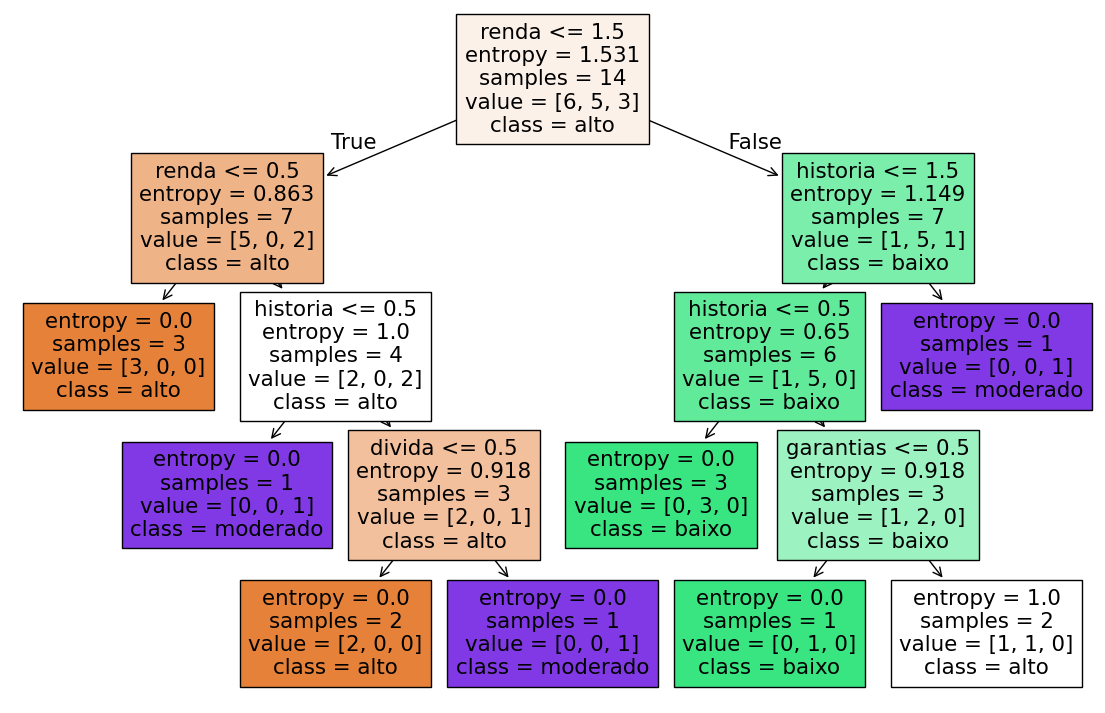

In [19]:
from sklearn import tree

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(14, 9))
tree.plot_tree(arvore_risco_credito,
               feature_names=previsores_risco,
               class_names=arvore_risco_credito.classes_,
               filled=True, ax=ax)
plt.show()

e) FAZER A PREVISÃO

Utilize .predict para fazer a previsão realizada no exemplo em sala.

   i. história boa, dívida alta, garantia nenhuma, renda > 35

   ii. história ruim, dívida alta, garantia adequada, renda < 15


Verifique nos slides se seu resultado está correto!

In [20]:
# Codificação (LabelEncoder da Parte 1):
#   historia : boa=0, desconhecida=1, ruim=2 | divida: alta=0, baixa=1
#   garantias: adequada=0, nenhuma=1         | renda : 0_15=0, 15_35=1, acima_35=2
# i)  [0, 0, 1, 2] -> baixo
# ii) [2, 0, 0, 0] -> alto
previsao = arvore_risco_credito.predict([[0, 0, 1, 2], [2, 0, 0, 0]])
print('i)  história boa, dívida alta, garantia nenhuma, renda > 35   ->', previsao[0])
print('ii) história ruim, dívida alta, garantia adequada, renda < 15 ->', previsao[1])

i)  história boa, dívida alta, garantia nenhuma, renda > 35   -> baixo
ii) história ruim, dívida alta, garantia adequada, renda < 15 -> alto


**Resposta:** i) **baixo**; ii) **alto**. Seguindo a árvore: no caso i, renda > 35 e história boa levam a *baixo*; no caso ii, renda < 15 leva diretamente a *alto*. Como a Parte 1 (Naïve Bayes) devolveu *moderado* para o caso ii, vale destacar na comparação que a árvore segue o raciocínio esperado do exemplo.

## 3 - Algoritmo de Árvore de Decisão para uma base de dados maior (Credit Data)

Nesta seção você deverá testar o uso da Árvore de Decisão para a Base de Dados Credit Risk Dataset. Aqui estaremos analisando os clientes que pagam (classe 0) ou não pagam a dívida (classe 1), a fim do banco conceder empréstimo.

In [21]:
# abrir o arquivo
with open('credit.pkl', 'rb') as f:
  X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(f)

a) Ao abrir o arquivo utilize .shape para verificar o tamanho dos dados de treinamento e de teste

OBS: os dados de treinamento devem ter as seguintes dimenções: x=(1500, 3), y=(1500,); os dados de teste devem ter as seguintes dimenções: x=(500, 3), y=(500,)

In [22]:
print('Treinamento: X =', X_credit_treinamento.shape, '| y =', y_credit_treinamento.shape)
print('Teste:        X =', X_credit_teste.shape, '| y =', y_credit_teste.shape)
assert X_credit_treinamento.shape == (1500, 3) and y_credit_treinamento.shape == (1500,)
assert X_credit_teste.shape == (500, 3) and y_credit_teste.shape == (500,)
print()
print('Classes no treinamento (0 = paga, 1 = não paga):', {int(k): int(v) for k, v in zip(*np.unique(y_credit_treinamento, return_counts=True))})
print('Classes no teste:                               ', {int(k): int(v) for k, v in zip(*np.unique(y_credit_teste, return_counts=True))})

Treinamento: X = (1500, 3) | y = (1500,)
Teste:        X = (500, 3) | y = (500,)

Classes no treinamento (0 = paga, 1 = não paga): {0: 1281, 1: 219}
Classes no teste:                                {0: 436, 1: 64}


b) Importe o pacote DecisionTreeClassifier do sklearn para treinar o seu algoritmo de árvore de decisão. Para poder refazer os testes e obter o mesmo resultado utilize o parâmetro random_state = 0.

In [23]:
# DecisionTreeClassifier já foi importado na seção 2.
# random_state=0 para reproduzir o resultado. Mantivemos criterion='entropy' (como na seção 2
# e na floresta); com o critério padrão 'gini' a acurácia no teste seria 98,0%.
arvore_credit = DecisionTreeClassifier(criterion='entropy', random_state=0)
arvore_credit.fit(X_credit_treinamento, y_credit_treinamento)

DecisionTreeClassifier(criterion='entropy', random_state=0)

c) Faça a previsão com os dados de teste. Visualize os dados e verifique se as previsões estão de acordo com os dados de teste (respostas reais).

In [24]:
previsoes = arvore_credit.predict(X_credit_teste)

print('Previsões (30 primeiros):', previsoes[:30])
print('Reais     (30 primeiros):', y_credit_teste[:30])
print()
print('Previsões diferentes das respostas reais:', int((previsoes != y_credit_teste).sum()), 'de', len(y_credit_teste))

Previsões (30 primeiros): [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0]
Reais     (30 primeiros): [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0]

Previsões diferentes das respostas reais: 9 de 500


d) Agora faça o cálculo da acurácia para calcular a taxa de acerto entre os valores reais (y teste) e as previsões

In [25]:
from sklearn.metrics import accuracy_score, classification_report
acuracia_arvore = accuracy_score(y_credit_teste, previsoes)
print(f'Acurácia da árvore de decisão: {acuracia_arvore:.4f} ({acuracia_arvore:.1%})')

Acurácia da árvore de decisão: 0.9820 (98.2%)


e) Faça a análise da Matriz de Confusão.

i. Quantos clientes foram classificados corretamente que pagam a dívida?

ii. Quantos clientes foram classificados incorretamente como não pagantes?

iii. Quantos clientes foram classificados corretamente que não pagam?

iv. Quantos clientes foram classificados incorretamente como pagantes?

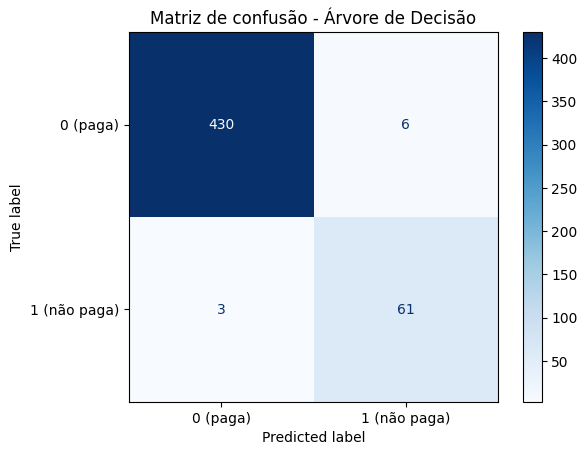

In [26]:
# Matriz de confusão (yellowbrick, como no enunciado). Se o yellowbrick não estiver
# instalado, usamos o ConfusionMatrixDisplay do scikit-learn, que gera a mesma matriz.
try:
    from yellowbrick.classifier import ConfusionMatrix
    cm = ConfusionMatrix(arvore_credit)
    cm.fit(X_credit_treinamento, y_credit_treinamento)
    cm.score(X_credit_teste, y_credit_teste)
except ImportError:
    from sklearn.metrics import ConfusionMatrixDisplay
    ConfusionMatrixDisplay.from_predictions(y_credit_teste, previsoes, cmap='Blues',
                                            display_labels=['0 (paga)', '1 (não paga)'])
    plt.title('Matriz de confusão - Árvore de Decisão')
    plt.show()

In [27]:
from sklearn.metrics import confusion_matrix
cm_arvore = confusion_matrix(y_credit_teste, previsoes)
print(cm_arvore)
print()
vn, fp, fn, vp = cm_arvore.ravel()
print(f'i.   Pagantes classificados corretamente como pagantes ....... {vn}')
print(f'ii.  Pagantes classificados incorretamente como não pagantes . {fp}')
print(f'iii. Não pagantes classificados corretamente como não pagantes {vp}')
print(f'iv.  Não pagantes classificados incorretamente como pagantes . {fn}')

[[430   6]
 [  3  61]]

i.   Pagantes classificados corretamente como pagantes ....... 430
ii.  Pagantes classificados incorretamente como não pagantes . 6
iii. Não pagantes classificados corretamente como não pagantes 61
iv.  Não pagantes classificados incorretamente como pagantes . 3


**Resposta (matriz de confusão da árvore):** linhas = classe real, colunas = classe prevista.

| | Previsto: paga (0) | Previsto: não paga (1) |
|---|---|---|
| **Real: paga (0)** | 430 | 6 |
| **Real: não paga (1)** | 3 | 61 |

i. **430** pagantes foram classificados corretamente. ii. **6** pagantes foram classificados incorretamente como não pagantes (bom cliente com crédito negado). iii. **61** não pagantes foram classificados corretamente. iv. **3** não pagantes foram classificados incorretamente como pagantes (o erro mais caro para o banco, pois o empréstimo seria concedido). Total de erros: 9 em 500.

f) Faça um print do parâmetro classification_report entre os dados de teste e as previsões. Explique qual é a relação entre precision e recall nos dados. Como você interpreta esses dados?

In [28]:
print(classification_report(y_credit_teste, previsoes, target_names=['0 (paga)', '1 (não paga)']))

              precision    recall  f1-score   support

    0 (paga)       0.99      0.99      0.99       436
1 (não paga)       0.91      0.95      0.93        64

    accuracy                           0.98       500
   macro avg       0.95      0.97      0.96       500
weighted avg       0.98      0.98      0.98       500



**Interpretação:**

- **Precision** responde: "de todos os clientes que o modelo previu como classe X, quantos realmente eram X?". **Recall** responde: "de todos os clientes que realmente são da classe X, quantos o modelo encontrou?".
- **Classe 0 (paga):** precision 0,99 e recall 0,99. O modelo quase não erra nessa classe, que é a maioria (436 de 500, ou 87,2%).
- **Classe 1 (não paga):** precision **0,91** (dos 67 previstos como não pagantes, 61 realmente eram) e recall **0,95** (dos 64 não pagantes reais, 61 foram encontrados). Aqui o recall é maior que a precision: a árvore prefere "pecar por excesso de cautela" (6 falsos alarmes) a deixar passar inadimplentes (apenas 3).
- Existe um *trade-off*: aumentar o recall de uma classe tende a reduzir sua precision, e vice-versa. O F1-score (0,93 na classe 1) resume os dois.
- Como as classes são desbalanceadas, a acurácia de 98,2% sozinha engana um pouco, pois um modelo que dissesse "todos pagam" já teria 87,2%. Por isso é importante olhar a classe 1 separadamente. Para o banco, o recall da classe 1 é o mais crítico (não conceder crédito a quem não vai pagar), e a árvore o mantém alto (95%).

g) Gere uma visualização da sua árvore de decisão utilizando o pacote tree da biblioteca do sklearn.

OBS 1: Os atributos previsores são = ['income', 'age', 'loan']

OBS 2: Adicione cores, nomes para os atributos e para as classes. Você pode utilizar a função fig.savefig para salvar a árvore em uma imagem .png

Profundidade da árvore: 8 | Número de folhas: 19


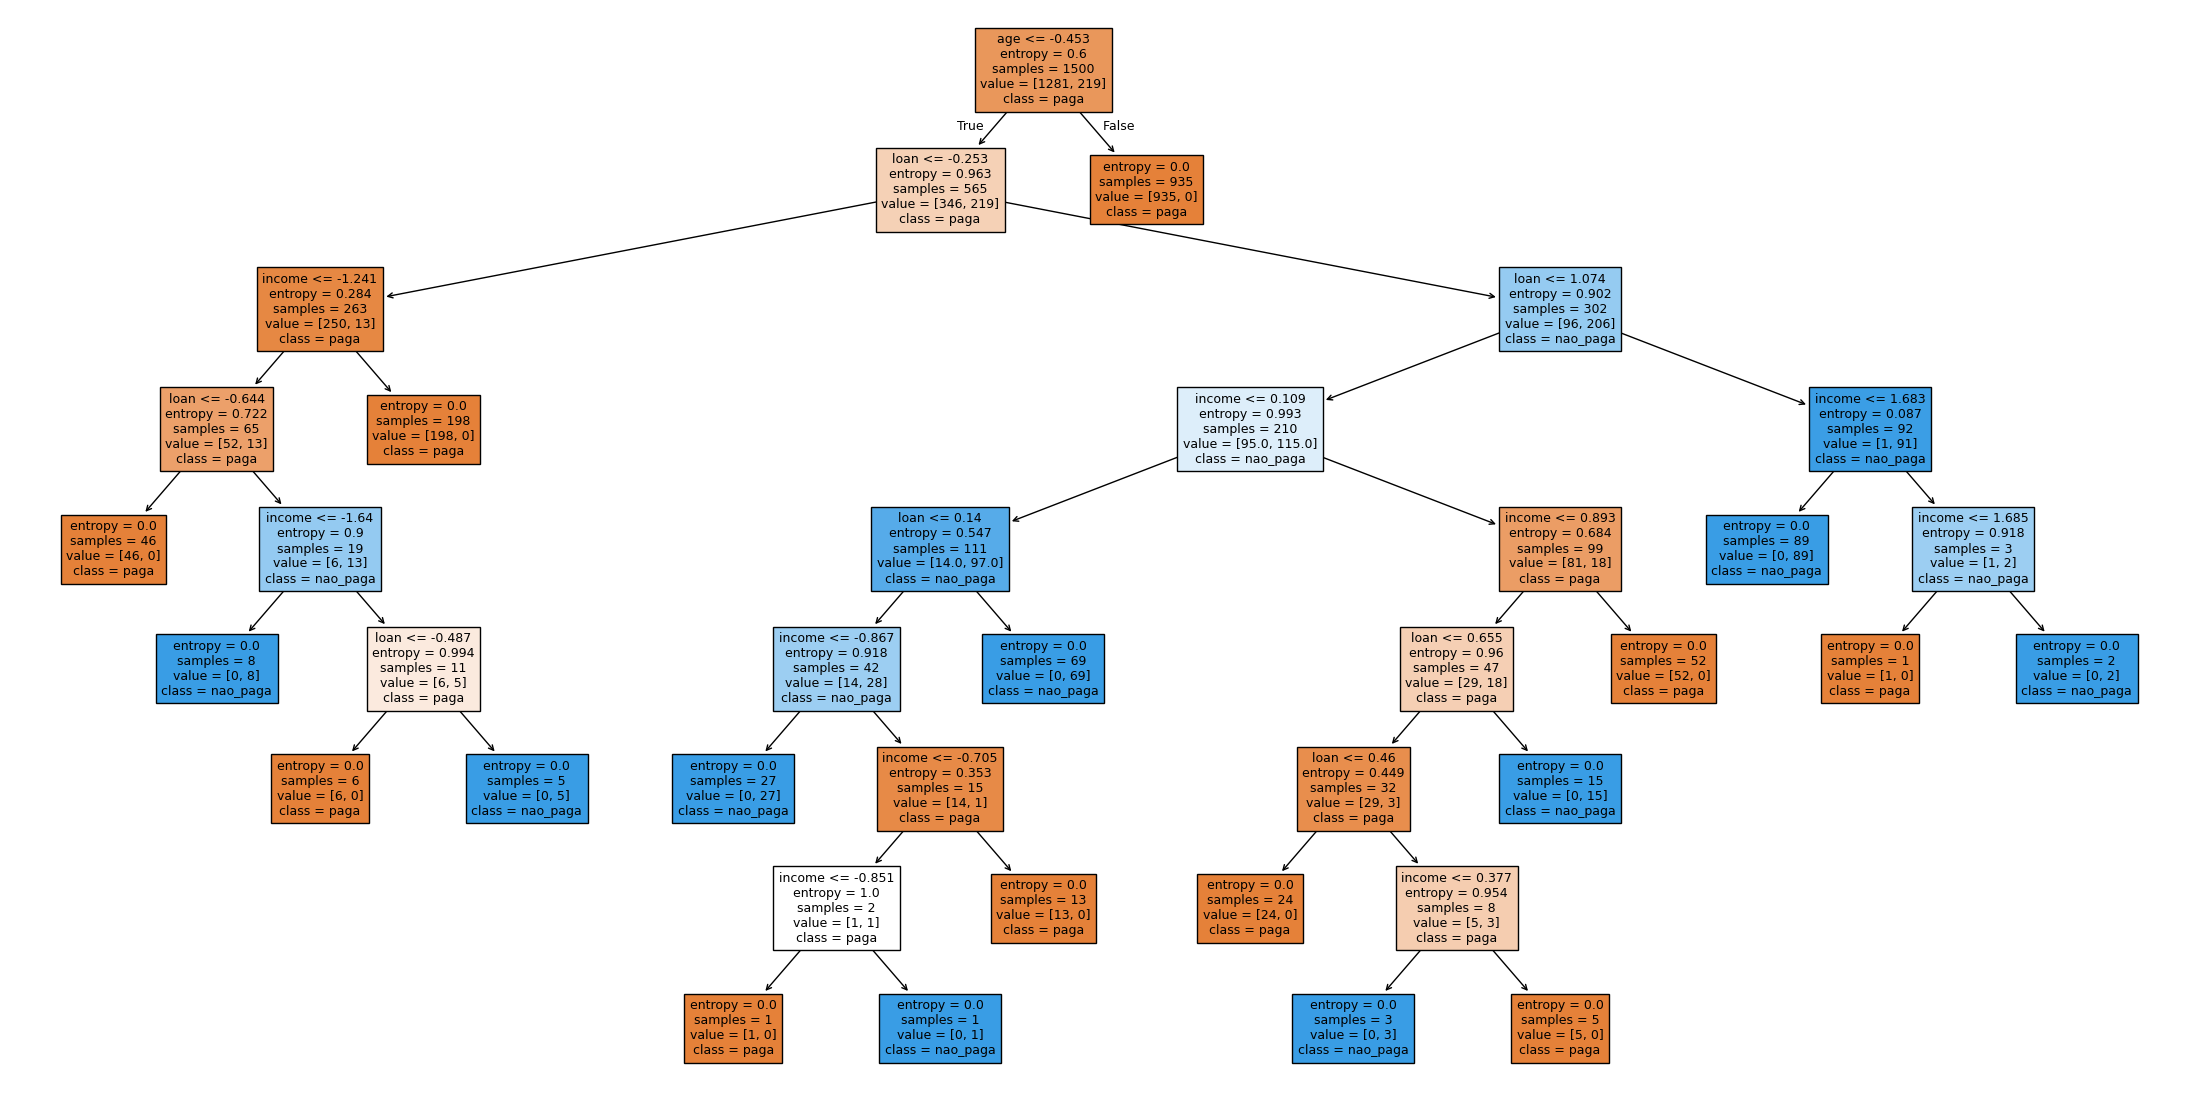

In [29]:
previsores_credit = ['income', 'age', 'loan']

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(28, 14))
tree.plot_tree(arvore_credit,
               feature_names=previsores_credit,
               class_names=['paga', 'nao_paga'],
               filled=True, ax=ax, fontsize=9)
fig.savefig('arvore_credit.png', dpi=150, bbox_inches='tight')
print('Profundidade da árvore:', arvore_credit.get_depth(), '| Número de folhas:', arvore_credit.get_n_leaves())
plt.show()

## Algoritmo Random Forest

Nesta seção iremos utilizar o algoritmo Random Forest para a mesma base de crédito (**Credit Risk Dataset**) - arquivo *credit.pkl*.

a) Importe o pacote RandomForestClassifier do sklearn para treinar o seu algoritmo de floresta randomica.

In [30]:
from sklearn.ensemble import RandomForestClassifier

b) Para gerar a classificação você deve adicionar alguns parâmetros:
*   n_estimators=10  --> número de árvores que você irá criar
*   criterion='entropy'
*   random_state = 0

In [31]:
floresta_credit = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
floresta_credit.fit(X_credit_treinamento, y_credit_treinamento)

RandomForestClassifier(criterion='entropy', n_estimators=10, random_state=0)

c) Faça a previsão com os dados de teste. Visualize os dados e verifique se as previsões estão de acordo com os dados de teste (respostas reais).

In [32]:
previsoes_floresta = floresta_credit.predict(X_credit_teste)

print('Previsões (30 primeiros):', previsoes_floresta[:30])
print('Reais     (30 primeiros):', y_credit_teste[:30])
print()
print('Previsões diferentes das respostas reais:', int((previsoes_floresta != y_credit_teste).sum()), 'de', len(y_credit_teste))

Previsões (30 primeiros): [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0]
Reais     (30 primeiros): [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0]

Previsões diferentes das respostas reais: 16 de 500


d) Agora faça o cálculo da acurácia para calcular a taxa de acerto entre os valores reais (y teste) e as previsões. O resultado foi melhor do que a árvore de decisão simples?

In [33]:
acuracia_floresta = accuracy_score(y_credit_teste, previsoes_floresta)
print(f'Acurácia da Random Forest (10 árvores): {acuracia_floresta:.4f} ({acuracia_floresta:.1%})')
print(f'Acurácia da Árvore de Decisão simples:   {acuracia_arvore:.4f} ({acuracia_arvore:.1%})')

Acurácia da Random Forest (10 árvores): 0.9680 (96.8%)
Acurácia da Árvore de Decisão simples:   0.9820 (98.2%)


**Resposta:** **não**. A floresta com 10 árvores obteve 96,8% de acurácia, abaixo dos 98,2% da árvore de decisão simples (16 erros contra 9 em 500).

e) Se o resultado foi inferior, como você poderia resolver isso? Quais foram os resultados obtidos?

In [34]:
# Hipótese: 10 árvores é um número pequeno; a força da floresta vem da média de muitas
# árvores. Testamos valores maiores de n_estimators (mesmos random_state e criterion).
from sklearn.metrics import recall_score

print('n_estimators | acurácia | recall da classe 1 (não paga)')
for n in [10, 25, 50, 100, 200, 500]:
    rf = RandomForestClassifier(n_estimators=n, criterion='entropy', random_state=0)
    rf.fit(X_credit_treinamento, y_credit_treinamento)
    prev = rf.predict(X_credit_teste)
    print(f'{n:12d} | {accuracy_score(y_credit_teste, prev):.3f}    | {recall_score(y_credit_teste, prev):.3f}')
print()
print(f'(Árvore de decisão simples: acurácia {acuracia_arvore:.3f} | recall classe 1 {recall_score(y_credit_teste, previsoes):.3f})')

n_estimators | acurácia | recall da classe 1 (não paga)
          10 | 0.968    | 0.812
          25 | 0.980    | 0.891
          50 | 0.980    | 0.891
         100 | 0.982    | 0.906
         200 | 0.982    | 0.906
         500 | 0.984    | 0.922

(Árvore de decisão simples: acurácia 0.982 | recall classe 1 0.953)


**Resposta:** o caminho é **aumentar o número de árvores** (`n_estimators`). Resultados obtidos:

| n_estimators | Acurácia | Recall (não paga) |
|---|---|---|
| 10 | 96,8% | 81,3% |
| 25 | 98,0% | 89,1% |
| 50 | 98,0% | 89,1% |
| **100** | **98,2%** | 90,6% |
| 200 | 98,2% | 90,6% |
| 500 | 98,4% | 92,2% |
| *Árvore simples* | *98,2%* | *95,3%* |

Com 100 árvores a floresta já **iguala** a árvore simples (98,2%) e a partir daí estabiliza; 500 árvores acrescentam apenas 1 acerto em 500, diferença pequena demais para ser considerada relevante. Adotamos **100 árvores** (valor padrão do scikit-learn, bom equilíbrio entre desempenho e custo) nas análises dos itens f) e g). Outras opções que poderiam ser exploradas: limitar `max_depth`, ajustar `max_features`/`min_samples_leaf` ou usar `class_weight='balanced'` para dar mais peso à classe minoritária.

Observe também que, nesta base, a floresta **não superou** a árvore: a base é pequena (1500 treinamentos), tem apenas 3 atributos e a árvore única já separa bem as classes, então o ganho típico do *ensemble* é limitado.

f) Faça a análise da Matriz de Confusão.

10 árvores : pagantes corretos=432 | pagantes marcados como não pagantes=4 | não pagantes corretos=52 | não pagantes marcados como pagantes=12
100 árvores: pagantes corretos=433 | pagantes marcados como não pagantes=3 | não pagantes corretos=58 | não pagantes marcados como pagantes=6


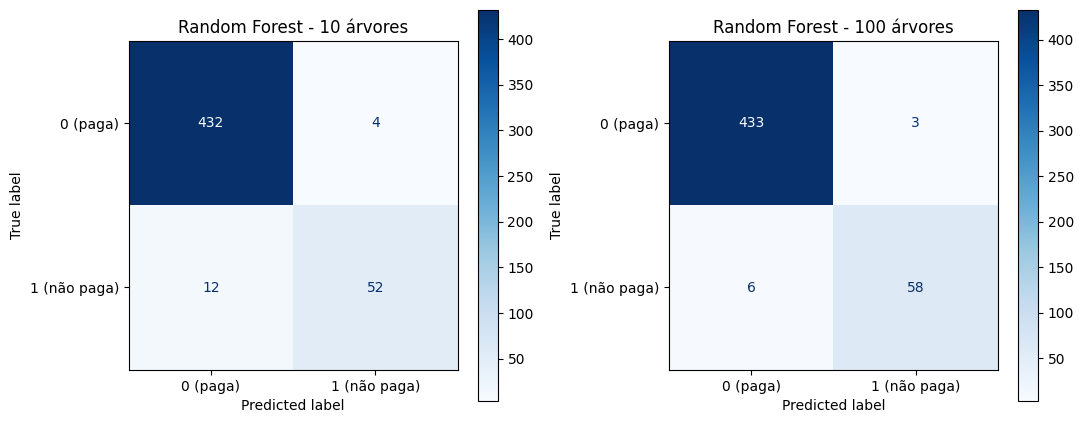

In [35]:
# Floresta final com 100 árvores (escolhida no item e)
floresta_credit_100 = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0)
floresta_credit_100.fit(X_credit_treinamento, y_credit_treinamento)
previsoes_floresta_100 = floresta_credit_100.predict(X_credit_teste)

from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, prev, titulo in [(axes[0], previsoes_floresta, 'Random Forest - 10 árvores'),
                         (axes[1], previsoes_floresta_100, 'Random Forest - 100 árvores')]:
    ConfusionMatrixDisplay.from_predictions(y_credit_teste, prev, cmap='Blues', ax=ax,
                                            display_labels=['0 (paga)', '1 (não paga)'])
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

for nome, prev in [('10 árvores', previsoes_floresta), ('100 árvores', previsoes_floresta_100)]:
    vn, fp, fn, vp = confusion_matrix(y_credit_teste, prev).ravel()
    print(f'{nome:11s}: pagantes corretos={vn} | pagantes marcados como não pagantes={fp} | '
          f'não pagantes corretos={vp} | não pagantes marcados como pagantes={fn}')

**Resposta:**

| Modelo | Pagantes corretos | Pagantes → "não paga" (erro) | Não pagantes corretos | Não pagantes → "paga" (erro) |
|---|---|---|---|---|
| Árvore de decisão | 430 | 6 | 61 | 3 |
| Floresta, 10 árvores | 432 | 4 | 52 | **12** |
| Floresta, 100 árvores | 433 | 3 | 58 | 6 |

A floresta de 10 árvores acerta um pouco mais os pagantes, mas deixa passar **12** não pagantes como se fossem bons clientes, o erro mais caro para o banco, e é isso que derruba sua acurácia. Com 100 árvores, esse erro cai para 6 e os falsos alarmes para 3; ainda assim a árvore simples erra menos nessa categoria (3).

g) Faça um print do parâmetro classification_report entre os dados de teste e as previsões. Explique qual é a relação entre precision e recall nos dados. Como você interpreta esses dados?

In [36]:
print('=== Random Forest - 10 árvores ===')
print(classification_report(y_credit_teste, previsoes_floresta, target_names=['0 (paga)', '1 (não paga)']))
print('=== Random Forest - 100 árvores ===')
print(classification_report(y_credit_teste, previsoes_floresta_100, target_names=['0 (paga)', '1 (não paga)']))

=== Random Forest - 10 árvores ===
              precision    recall  f1-score   support

    0 (paga)       0.97      0.99      0.98       436
1 (não paga)       0.93      0.81      0.87        64

    accuracy                           0.97       500
   macro avg       0.95      0.90      0.92       500
weighted avg       0.97      0.97      0.97       500

=== Random Forest - 100 árvores ===
              precision    recall  f1-score   support

    0 (paga)       0.99      0.99      0.99       436
1 (não paga)       0.95      0.91      0.93        64

    accuracy                           0.98       500
   macro avg       0.97      0.95      0.96       500
weighted avg       0.98      0.98      0.98       500



**Interpretação:**

- **Floresta com 10 árvores:** na classe 1 (não paga) a precision é **0,93** (52 de 56 previstos estavam certos), mas o recall é só **0,81** (52 de 64 não pagantes encontrados). O modelo é "conservador": quando diz que o cliente não paga, quase sempre acerta, mas deixa escapar quase 1 em cada 5 inadimplentes. O F1 da classe 1 é 0,87, o pior dos modelos testados.
- **Floresta com 100 árvores:** precision **0,95** e recall **0,91** na classe 1 (F1 = 0,93). O recall sobe 10 pontos percentuais e a precision também, ou seja, o modelo melhora nas duas métricas ao ter mais árvores votando.
- **Comparação com a árvore simples:** a árvore tem precision 0,91 e recall 0,95 na classe 1. A floresta de 100 árvores inverte esse perfil: é **mais precisa** (menos falsos alarmes) e tem **recall menor** (deixa passar mais inadimplentes). O F1 é igual (0,93) e a acurácia também (98,2%).
- **Relação precision × recall:** é um *trade-off*. Quanto mais o modelo evita acusar um bom cliente (precision alta), mais tende a deixar escapar inadimplentes (recall menor), e vice-versa. Para o banco, o custo de conceder crédito a quem não paga costuma ser maior que o de recusar um bom cliente. Se esse for o critério, o **recall da classe 1** deve ter prioridade, o que favorece a árvore simples ou uma floresta com `class_weight='balanced'`.
- Como o teste tem só 64 casos de classe 1, diferenças de 1 ou 2 clientes mudam as métricas visivelmente; vale confirmar com validação cruzada antes de tirar conclusões definitivas.

## Respostas resumidas - Parte 2

| Modelo | Acurácia (teste) | Erros em 500 | Precision / Recall (classe 1) |
|---|---|---|---|
| Árvore de decisão (entropia, `random_state=0`) | 98,2% | 9 | 0,91 / 0,95 |
| Random Forest, 10 árvores | 96,8% | 16 | 0,93 / 0,81 |
| Random Forest, 100 árvores | 98,2% | 9 | 0,95 / 0,91 |

Todas as métricas usam os rótulos reais de teste apenas na avaliação. A árvore da Parte 2 (seção 2) usa `renda` como atributo mais importante e prevê *baixo* e *alto* para os dois casos do exemplo de aula.